# ¿Cómo se distribuyen los titulares de La República entre cuatro temas?

**Fecha de descarga:** 2026-10-17T09:10:19-05:00. **Opción A:** La República.

**URLs base:** https://larepublica.pe/robots.txt, https://larepublica.pe/rss/politica.xml,
https://larepublica.pe/rss/economia.xml, https://larepublica.pe/rss/deportes.xml,
https://larepublica.pe/rss/ciencia.xml; sitemaps y secciones públicas de política, economía,
deportes, ciencia y tecnología. Los enlaces relacionados del propio medio amplían el período.

Meta: 400 noticias reales (~100 por categoría). La muestra tiene cuotas y depende de los enlaces
accesibles: no estima la proporción natural de temas publicada por el periódico.

## 1. Configuración y reproducción

El recolector en `src/recoleccion.py` consulta `robots.txt` con Protego (incluye comodines),
identifica su User-Agent, hace solicitudes secuenciales con pausas de 1,5–2 segundos,
como máximo un reintento y guarda XML/HTML y metadatos en `datos/raw/`.
No usa páginas restringidas de archivo ni construye rutas de paginación.

`RECOLECTAR = False` permite analizar el CSV entregado sin volver a consultar el sitio.
Cambiarlo a `True` ejecuta la recolección; la caché evita descargar otra vez las mismas URLs.
Para una nueva fecha de extracción usar una carpeta de datos nueva y conservar la anterior.

In [1]:
from pathlib import Path
import json
import os
import platform
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display
from src.recoleccion import collect, COLUMNS, CATEGORIES, SECTION_MAP, section_key

ROOT = Path.cwd()
assert (ROOT / 'datos').exists(), 'Ejecutar el notebook desde tarea_1/'
# Edge permite que Kaleido genere una imagen junto a la figura interactiva.
edge = Path(os.environ.get('PROGRAMFILES(X86)', 'C:/Program Files (x86)')) / 'Microsoft/Edge/Application/msedge.exe'
if edge.exists():
    os.environ.setdefault('BROWSER_PATH', str(edge))
pio.renderers.default = 'plotly_mimetype+png'
pio.templates.default = 'plotly_white'
pd.set_option('display.max_colwidth', None)
print('Python:', platform.python_version())
RECOLECTAR = False
if RECOLECTAR:
    df, resumen = collect(per_category=100)
else:
    df = pd.read_csv(ROOT / 'datos/noticias.csv', keep_default_na=False)
    resumen = json.loads((ROOT / 'datos/resumen_recoleccion.json').read_text(encoding='utf-8'))
display(pd.DataFrame({'indicador': ['Noticias finales', 'Enlaces candidatos únicos', 'URLs finales con HTTP 200'],
                      'valor': [len(df), resumen['candidatos_unicos'], resumen['url_verificadas_http_200']]}))
display(pd.DataFrame(list(resumen['fuentes'].items()), columns=['fuente', 'entradas_descubiertas']))

Python: 3.13.5


,indicador,valor
0,Noticias finales,400
1,Enlaces candidatos únicos,2269
2,URLs finales con HTTP 200,400


,fuente,entradas_descubiertas
0,https://larepublica.pe/rss/politica.xml,26
1,https://larepublica.pe/sitemap/politica.xml,26
2,https://larepublica.pe/rss/economia.xml,14
3,https://larepublica.pe/sitemap/economia.xml,14
4,https://larepublica.pe/rss/deportes.xml,13
5,https://larepublica.pe/sitemap/deportes.xml,13
6,https://larepublica.pe/rss/ciencia.xml,7
7,https://larepublica.pe/sitemap/ciencia.xml,7
8,https://larepublica.pe/politica,17
9,https://larepublica.pe/economia,19


## 2. Limpieza, equivalencias y descartes

La categoría de referencia procede de la sección de origen. Ciencia y tecnología se agrupan
en `ciencia_tecnologia`; no se crea una quinta clase. Se conserva el nombre original de sección.
La tabla incluye la ruta para desambiguar nombres de subsección que podrían repetirse.

Se eliminan URLs repetidas durante el descubrimiento y titulares vacíos, duplicados o casi
idénticos (similitud de caracteres ≥ 0,95). La bajada procede de RSS o metadatos HTML, nunca
de generación artificial. Los errores y descartes se guardan con motivo; los candidatos que no
se descargan porque la cuota ya está completa no se presentan como noticias recolectadas.

In [2]:
mapeo = pd.read_csv('datos/mapeo_secciones.csv', keep_default_na=False)
display(mapeo)
print('Regla explícita por ruta:', SECTION_MAP)
descartes = pd.read_csv('datos/descartes.csv', keep_default_na=False)
descubrimiento = pd.read_csv('datos/descartes_descubrimiento.csv', keep_default_na=False)
print('Descartes durante extracción:', len(descartes))
display(descartes.groupby('motivo').size().rename('cantidad').reset_index())
print('Duplicados/fuera de alcance detectados en descubrimiento:', len(descubrimiento))
display(descubrimiento.groupby('motivo').size().rename('cantidad').reset_index())
controles = pd.DataFrame({
    'control': ['Siete columnas exactas', '350 o más noticias', 'Cuatro categorías oficiales',
                'Sin URLs duplicadas', 'Sin titulares vacíos', 'Sin bajadas vacías', 'Mapeo consistente con ruta'],
    'cumple': [list(df.columns) == COLUMNS, len(df) >= 350, set(df.etiqueta) == set(CATEGORIES),
               not df.url.duplicated().any(), df.titular.str.strip().ne('').all(),
               df.bajada.str.strip().ne('').all(),
               df.apply(lambda r: SECTION_MAP.get(section_key(r.url)) == r.etiqueta, axis=1).all()]})
display(controles)
assert controles.cumple.all(), 'Revisar controles fallidos antes de modelar'

,ruta_seccion,seccion_original,etiqueta
0,ciencia,Ciencia,ciencia_tecnologia
1,deportes,Deportes,deportes
2,economia,Economía,economia
3,economia,Precio del dólar,economia
4,politica,Política,politica
5,tecnologia,Tecnología,ciencia_tecnologia


Regla explícita por ruta: {'politica': 'politica', 'economia': 'economia', 'deportes': 'deportes', 'ciencia': 'ciencia_tecnologia', 'tecnologia': 'ciencia_tecnologia'}
Descartes durante extracción: 115


,motivo,cantidad
0,404 Client Error: Not Found for url: https://larepublica.pe/ciencia/2026/09/16/el-sol-podria-ocultar-las-huellas-de-un-planeta-desaparecido-hasta-10-veces-mas-masivo-que-la-tierra-1243568,1
1,publicacion_anterior_a_2026-01-01,98
2,titular_casi_duplicado_095,13
3,titular_duplicado,3


Duplicados/fuera de alcance detectados en descubrimiento: 60


,motivo,cantidad
0,url_repetida_descubrimiento,60


,control,cumple
0,Siete columnas exactas,True
1,350 o más noticias,True
2,Cuatro categorías oficiales,True
3,Sin URLs duplicadas,True
4,Sin titulares vacíos,True
5,Sin bajadas vacías,True
6,Mapeo consistente con ruta,True


## 3. Análisis exploratorio con Plotly Express

Las figuras conservan su salida interactiva y una imagen estática para la lectura en GitHub.
Los títulos se calculan a partir de los datos. La distribución por categoría refleja una decisión
de muestreo por cuotas, no una conclusión sobre la agenda editorial del medio.

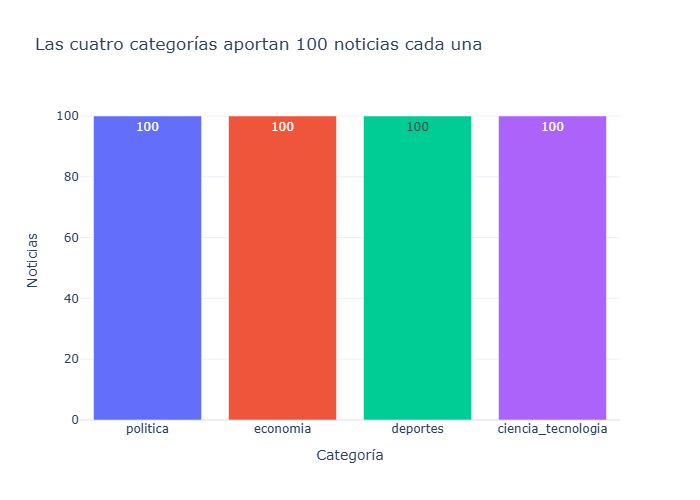

In [3]:
por_categoria = df.etiqueta.value_counts().reindex(CATEGORIES).rename_axis('categoria').reset_index(name='noticias')
titulo = ('Las cuatro categorías aportan ' + str(int(por_categoria.noticias.iloc[0])) + ' noticias cada una'
          if por_categoria.noticias.nunique() == 1 else 'La muestra tiene diferencias de tamaño entre categorías')
fig = px.bar(por_categoria, x='categoria', y='noticias', color='categoria',
             title=titulo, text_auto=True, labels={'categoria': 'Categoría', 'noticias': 'Noticias'})
fig.update_layout(showlegend=False)
fig.show()

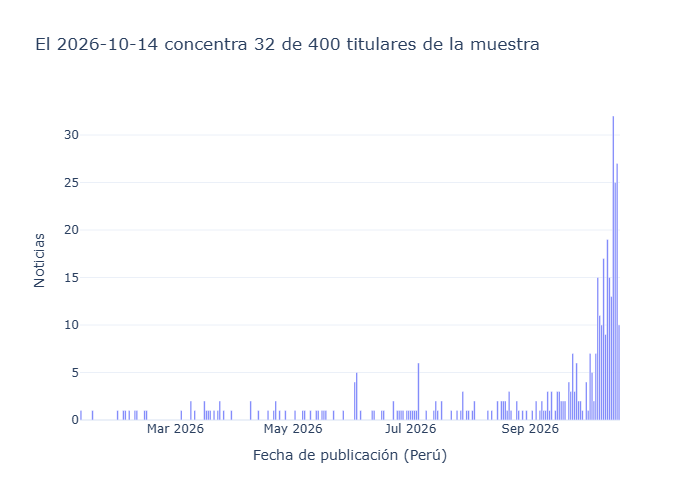

Período de publicación: 2026-01-11 a 2026-10-17


In [4]:
por_fecha = df.groupby('fecha').size().rename('noticias').reset_index().sort_values('fecha')
pico = por_fecha.loc[por_fecha.noticias.idxmax()]
fig = px.bar(por_fecha, x='fecha', y='noticias',
             title=f"El {pico['fecha']} concentra {int(pico['noticias'])} de {len(df)} titulares de la muestra",
             labels={'fecha': 'Fecha de publicación (Perú)', 'noticias': 'Noticias'})
fig.show()
print('Período de publicación:', df.fecha.min(), 'a', df.fecha.max())

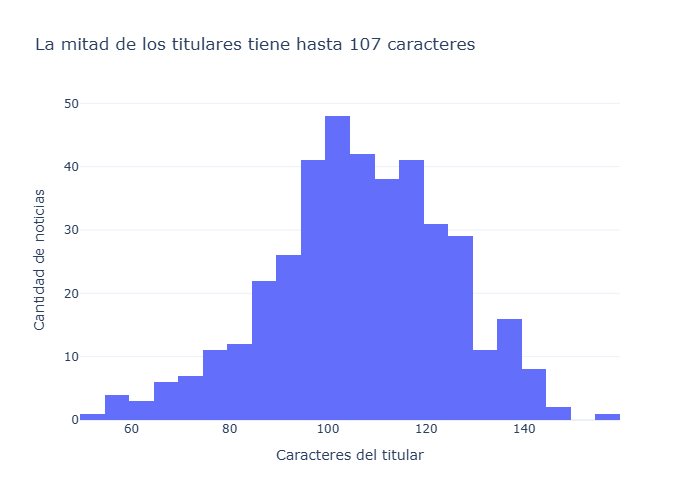

,caracteres
count,400.000000
mean,106.642500
std,18.361988
min,53.000000
25%,96.000000
50%,107.000000
75%,119.000000
max,158.000000


In [5]:
longitud = df.titular.str.len()
fig = px.histogram(x=longitud, nbins=25,
                   title=f'La mitad de los titulares tiene hasta {longitud.median():.0f} caracteres',
                   labels={'x': 'Caracteres del titular', 'y': 'Cantidad de noticias'})
fig.update_layout(yaxis_title='Cantidad de noticias')
fig.show()
display(longitud.describe().rename('caracteres').to_frame())

## 4. Validación de los extremos

Los ejemplos permiten comprobar si los valores extremos del histograma son titulares reales
y no errores de extracción. Se muestran sus enlaces y longitudes exactas.

In [6]:
extremos = df.assign(caracteres=df.titular.str.len())
print('Cinco titulares más cortos:')
display(extremos.nsmallest(5, 'caracteres')[['titular', 'caracteres', 'etiqueta', 'url']])
print('Cinco titulares más largos:')
display(extremos.nlargest(5, 'caracteres')[['titular', 'caracteres', 'etiqueta', 'url']])

Cinco titulares más cortos:


,titular,caracteres,etiqueta,url
288,Movistar: Más de 100 comunidades rurales acceden a 4G,53,economia,https://larepublica.pe/economia/2026/05/14/movistar-mas-de-100-comunidades-rurales-acceden-a-4g-hnews-987770
122,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?,57,deportes,https://larepublica.pe/deportes/2026/10/13/cuando-inicia-la-liga-peruana-de-voley-femenino-202627-423826
376,Hackean cuenta de X del Ministerio de Economía y Finanzas,57,politica,https://larepublica.pe/politica/2026/09/14/hackean-cuenta-de-x-del-ministerio-de-economia-y-finanzas-hnews-992502
352,JNE deberá resolver 21 casos de reeleción inconstitucional,58,politica,https://larepublica.pe/politica/2026/10/09/elecciones-regionales-jne-debera-resolver-21-casos-de-reelecion-inconstitucional-hnews-713709
360,Pugnas políticas entre militantes de Fuerza Popular en Puno,59,politica,https://larepublica.pe/politica/2026/10/09/pugnas-politicas-entre-militantes-de-fuerza-popular-en-puno-hnews-740934


Cinco titulares más largos:


,titular,caracteres,etiqueta,url
44,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200",158,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/09/30/la-humanidad-roza-sus-limites-la-poblacion-mundial-alcanzaria-los-12400-millones-en-2070-mientras-cientificos-sugieren-reducirla-a-4000-millones-para-2200-838170
21,"Australia recuperó sus praderas marinas tras un ciclón y grandes inundaciones, pero los científicos descubrieron que los peces ya no eran los mismos",148,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/10/12/australia-recupero-sus-praderas-marinas-tras-un-ciclon-y-grandes-inundaciones-pero-los-cientificos-descubrieron-que-los-peces-ya-no-eran-los-mismos-126384
104,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Copa Libertadores Femenina: ""Estuvimos cerca""",148,deportes,https://larepublica.pe/deportes/2026/10/16/mia-shalit-arquera-de-universitario-destaca-el-nivel-de-las-cremas-pese-a-derrota-ante-palmeiras-por-copa-libertadores-femenina-estuvimos-cerca-600528
19,"Un efecto visto en ‘Dragon Ball’, pero con insectos: moscas de frutas entrenadas con gravedad extrema se vuelven más resistentes e hiperactivas",143,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/10/14/un-efecto-visto-en-dragon-ball-pero-con-insectos-moscas-de-frutas-entrenadas-con-gravedad-extrema-se-vuelven-mas-resistentes-e-hiperactivas-901600
57,"El mayor volcán del sistema solar casi triplica la altura del Everest en la Tierra: creció sin placas tectónicas, aunque su planeta sí tiembla",142,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/08/31/el-volcan-mas-grande-del-sistema-solar-casi-triplica-al-everest-crecio-sin-placas-tectonicas-aunque-en-su-planeta-si-ocurren-sismos-2979255


## 5. Exportación y límites

Se entregan exactamente las siete columnas requeridas. El archivo de candidatos, el registro
de solicitudes y las tablas de limpieza conservan la trazabilidad fuera del CSV principal.

Limitaciones: muestreo por cuotas/enlaces accesibles, un solo medio y etiquetas editoriales
que pueden mezclar asuntos políticos y económicos. Las fechas y tamaños de las categorías
dependen de la disponibilidad del sitio durante la descarga. Un enlace con HTTP 200 se
verificó al recolectar; su disponibilidad futura puede cambiar.

In [7]:
df[COLUMNS].to_csv('datos/noticias.csv', index=False, encoding='utf-8')
print('df.shape =', df.shape)
display(df.head(5))

df.shape = (400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Científicos descubren una nueva especie de flor albiceleste en los andes peruanos y la nombraron en honor a Lionel Messi,"El color de los pétalos evoca la camiseta de la selección de fútbol, que vistió el famoso futbolista argentino.",La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/cientificos-descubren-una-nueva-especie-de-flor-albiceleste-en-los-andes-peruanos-y-la-nombraron-en-honor-a-lionel-messi-1575520,2026-10-16,ciencia_tecnologia
1,"El sistema solar se desintegraría mucho antes de lo previsto: después de todo, Newton se equivocó",Los planetas más grandes podrían entrar en un caos orbital mucho antes de la muerte de nuestra estrella.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/el-sistema-solar-se-desintegraria-mucho-antes-de-lo-previsto-despues-de-todo-newton-se-equivoco-1090320,2026-10-16,ciencia_tecnologia
2,"La Antártida se encuentra cubierta de hielo de hasta 4 km de espesor, pero no se compara en nada con lo que orbita cerca de Júpiter",Las mediciones brindan información sobre un mundo congelado que albergaría un océano líquido oculto bajo la enorme capa de hielo.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/la-antartida-se-encuentra-cubierta-de-hielo-de-hasta-4-km-de-espesor-pero-no-se-compara-en-nada-con-lo-que-orbita-cerca-de-jupiter-667888,2026-10-16,ciencia_tecnologia
3,Un estudio científico advierte sobre las bolsas de té: algunas liberan miles de millones de partículas de plástico durante la preparación,"El estudio plantea preguntas sobre los efectos de los microplásticos en la salud, aunque no se establece un vínculo directo con enfermedades.",La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/un-estudio-cientifico-advierte-sobre-las-bolsas-de-te-algunas-liberan-miles-de-millones-de-particulas-de-plastico-durante-la-preparacion-996375,2026-10-16,ciencia_tecnologia
4,Un lagarto de la época de los dinosaurios perdió su cola hace 99 millones de años y el ámbar conservó la evidencia,El fósil demuestra que este mecanismo de defensa ya estaba presente en estos reptiles del Cretácico medio.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/un-lagarto-de-la-epoca-de-los-dinosaurios-perdio-su-cola-hace-99-millones-de-anos-y-el-ambar-conservo-la-evidencia-1288416,2026-10-16,ciencia_tecnologia
